# Employee Attrition Analysis
**Prepared for:** Director of Human Resources

## 1. Prepare the Data and Measure Attrition

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# Set visual style for plots
sns.set_theme(style="whitegrid")

# 1. Import the CSV using pandas (make sure filename matches HR_comma_sep.csv)
df = pd.read_csv('HR_comma_sep.csv')

# Display rows and columns
print(f"Dataset Dimensions: {df.shape[0]:,} rows and {df.shape[1]} columns\n")

# Check for missing values in the columns we will analyze
cols_to_analyze = ['left', 'satisfaction_level', 'average_montly_hours', 'last_evaluation']
print("Missing values in analyzed columns:")
print(df[cols_to_analyze].isnull().sum())

# 2. Keep original 'left' column and create 'employment_status'
df['employment_status'] = np.where(df['left'] == 0, 'Stayed', 'Left')

# 3. Show count and percentage of employees in each group
status_counts = df['employment_status'].value_counts()
status_pcts = df['employment_status'].value_counts(normalize=True) * 100

attrition_summary = pd.DataFrame({
    'Count': status_counts,
    'Percentage (%)': status_pcts.round(2)
})
print("\nEmployment Status Summary:")
display(attrition_summary)

Dataset Dimensions: 14,999 rows and 10 columns

Missing values in analyzed columns:
left                    0
satisfaction_level      0
average_montly_hours    0
last_evaluation         0
dtype: int64

Employment Status Summary:


,Count,Percentage (%)
employment_status,,
Stayed,11428,76.19
Left,3571,23.81


**Attrition Summary:**  
Overall employee attrition is **23.81%** (3,571 employees), which was calculated using the total workforce of **14,999 employees** in the dataset as the denominator.

## 2. Compare Employees Who Left with Those Who Stayed
**Chosen Measure:** Employee Satisfaction (`satisfaction_level`, measured on a 0 to 1 scale).  

**Why This Matters to HR:**  
Monitoring employee satisfaction gives HR an early warning sign of disengagement and burnout before workers actually resign. Understanding whether departing employees report systematically lower satisfaction helps HR target retention initiatives and workplace improvements where they are needed most.

Satisfaction Level Summary by Employment Status:


,Count,Mean,Median,Std_Dev
employment_status,,,,
Left,3571,0.4401,0.41,0.2639
Stayed,11428,0.6668,0.69,0.2171


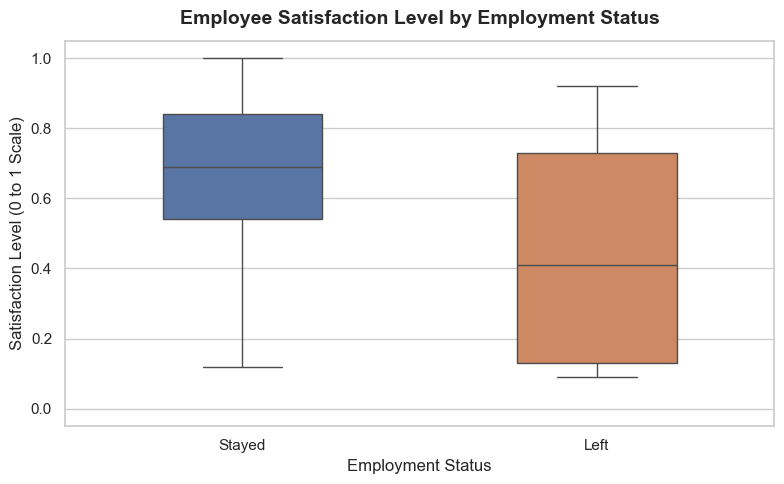

In [2]:
# Summary table showing count, mean, median, and standard deviation by group
sat_summary = df.groupby('employment_status')['satisfaction_level'].agg(
    Count='count',
    Mean='mean',
    Median='median',
    Std_Dev='std'
).round(4)

print("Satisfaction Level Summary by Employment Status:")
display(sat_summary)

# Create side-by-side boxplots
plt.figure(figsize=(8, 5))
sns.boxplot(
    data=df,
    x='employment_status',
    y='satisfaction_level',
    order=['Stayed', 'Left'],
    hue='employment_status',
    palette={'Stayed': '#4C72B0', 'Left': '#DD8452'},
    legend=False,
    width=0.45
)

plt.title('Employee Satisfaction Level by Employment Status', fontsize=14, fontweight='bold', pad=12)
plt.xlabel('Employment Status', fontsize=12)
plt.ylabel('Satisfaction Level (0 to 1 Scale)', fontsize=12)
plt.ylim(-0.05, 1.05)
plt.tight_layout()
plt.show()

**Distribution Comparison:**  
Employees who left exhibit noticeably lower typical satisfaction and a wider overall spread than those who stayed. Specifically, the median satisfaction score for the **Left** group (**0.41**) sits well below the median for the **Stayed** group (**0.69**), and the interquartile range (the middle 50% box) is much broader for employees who left (spanning roughly 0.13 to 0.73), showing that departing staff include both severely dissatisfied workers and a smaller cluster of fairly satisfied leavers.

## 3. Test the Difference in Means
**Hypotheses:**
* **Null Hypothesis ($H_0$):** There is no difference in the true average satisfaction level between employees who left and employees who stayed.
* **Alternative Hypothesis ($H_a$):** There is a difference in the true average satisfaction level between employees who left and employees who stayed.

In [3]:
# Separate groups (Left group first, as requested)
left_group = df[df['employment_status'] == 'Left']['satisfaction_level']
stayed_group = df[df['employment_status'] == 'Stayed']['satisfaction_level']

# Calculate mean difference (Left minus Stayed)
mean_diff = left_group.mean() - stayed_group.mean()

# Run two-sided Welch's independent-samples t-test (equal_var=False)
t_stat, p_val = stats.ttest_ind(left_group, stayed_group, equal_var=False, alternative='two-sided')

print(f"Mean Difference (Left - Stayed): {mean_diff:.4f}")
print(f"Welch's t-statistic:             {t_stat:.4f}")
print(f"p-value:                         {p_val:.4e}")

Mean Difference (Left - Stayed): -0.2267
Welch's t-statistic:             -46.6364
p-value:                         0.0000e+00


**Technical Interpretation ($\alpha = 0.05$):**  
Because the p-value ($p < 1.0 \times 10^{-300}$, reported as `0.0000e+00` due to floating-point precision limits) is well below the significance level of $\alpha = 0.05$, we reject the null hypothesis. There is statistically significant evidence of a difference in mean satisfaction levels between the two groups ($t = -46.64$).

**Plain-Language Explanation for the HR Director:**  
The gap in job satisfaction between employees who resigned and those who remained is far too large to be explained by random day-to-day variation. On average, employees who **stayed** had a higher satisfaction score (**0.67**) than employees who **left** (**0.44**)—a difference of **0.23 points** on the 0-to-1 satisfaction scale (roughly a 23-percentage-point drop).

## 4. Investigate Hours and Evaluations

Pearson's r: 0.3397
p-value:     0.0000e+00


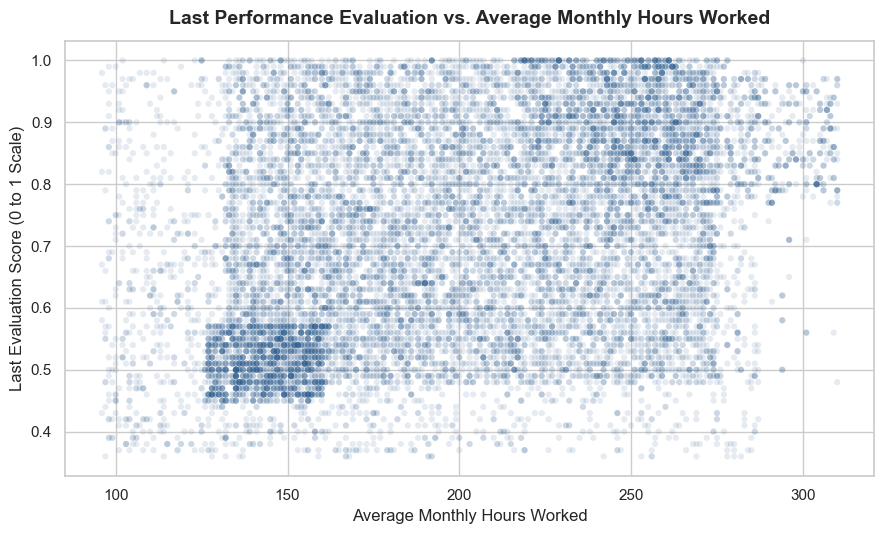

In [4]:
# Calculate Pearson's correlation across all employees
r_val, p_corr = stats.pearsonr(df['average_montly_hours'], df['last_evaluation'])

print(f"Pearson's r: {r_val:.4f}")
print(f"p-value:     {p_corr:.4e}")

# Create scatterplot with marker transparency (alpha)
plt.figure(figsize=(9, 5.5))
plt.scatter(
    df['average_montly_hours'],
    df['last_evaluation'],
    alpha=0.12,
    color='#2b5c8f',
    edgecolors='none',
    s=20
)

plt.title('Last Performance Evaluation vs. Average Monthly Hours Worked', fontsize=14, fontweight='bold', pad=12)
plt.xlabel('Average Monthly Hours Worked', fontsize=12)
plt.ylabel('Last Evaluation Score (0 to 1 Scale)', fontsize=12)
plt.tight_layout()
plt.show()

**Answer to the Director's Question:**  
Employees who work longer hours show only a **weak-to-moderate positive tendency** to receive higher performance evaluations ($r = 0.34$). In the scatterplot, while high-hour workers (around 240–310 hours/month) cluster more heavily toward upper evaluation scores (0.80–1.00), employees working standard hours (130–220 hours/month) span virtually the entire range of evaluation scores from 0.36 to 1.00.

**Statistical Significance vs. Practical Informativeness:**  
Although the correlation is highly statistically significant ($p < 1.0 \times 10^{-300}$) because of our very large sample size of 14,999 records, monthly hours alone tell HR relatively little about an individual employee's evaluation score. Working longer hours accounts for only about 11.5% ($r^2 = 0.115$) of the variation in evaluation ratings, meaning two employees working the exact same number of hours can receive very different performance reviews.

## 5. HR Briefing
Across our 14,999 employee records, 23.81% of staff left the company, and those who departed recorded an average satisfaction score that was 0.23 points lower on a 0-to-1 scale than those who stayed (0.44 vs. 0.67). In addition, while longer monthly work hours have a modest positive association with higher performance evaluations ($r = 0.34$), work hours alone do not reliably predict how well an individual employee is rated. Because these records reflect historical snapshots rather than controlled experiments, we cannot conclude from this data alone that low satisfaction directly caused resignations or that working extra hours caused higher ratings. As a next step, HR should investigate exit-interview themes or departmental workload differences among the subset of high-satisfaction employees who still chose to leave, as well as the drivers behind high-hour burnout.